# Q3. Reported Weather and Crash Injury

**Course** — CSC17104 · Programming for Data Science  
**Group** — Group 14 · Tam Khuyển  
**Question owner** — Lê Việt Hải (24127029)  
**Scope** — Non-ML · 2018–2024 comparison period  
**Dataset** — Traffic Accidents, Chicago (Kaggle snapshot)  
**Prerequisite** — Run [notebook 01](01_collection_exploration.ipynb) to generate `data/processed/traffic_accidents_clean.csv`.  
**Assistance log** — [LLM_USAGE.md](../LLM_USAGE.md)

## Introduction

**Research questions**

- **Q3** — How do injury shares for rain and snow compare with clear weather on similar road surfaces and under similar lighting? How closely do the reported labels align with daily weather at Chicago O’Hare?

**Motivation**

Traffic-safety researchers can use the comparisons to prioritize weather conditions for further study and assess how well a single station represents crash-site conditions.

**Analysis plan**

Join the NOAA station data by calendar day (D1), compare supported road-surface and lighting groups (D4), and estimate uncertainty by resampling weeks (D5). Any reported injury is the primary outcome. Fatal or incapacitating injury is the secondary outcome.

## External data and definitions

- **Source:** Menne et al. (2012), NOAA National Centers for Environmental Information, [Global Historical Climatology Network Daily (GHCN-Daily v3)](https://doi.org/10.7289/V5D21VHZ), [Chicago O’Hare International Airport, station USW00094846](https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND%3AUSW00094846/detail).
- **Input:** `data/reference/ohare_ghcn_daily_2018_2024.csv`, a dated subset of the [station archive](https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_station/USW00094846.csv.gz) retrieved 2026-11-20. The subset preserves the values and the measurement, quality, source and observation-time fields for PRCP and SNOW and places each date on one row. The smaller snapshot makes the notebook runnable offline.
- **Reuse and credit:** The [product metadata and use constraints](https://www.ncei.noaa.gov/metadata/geoportal/rest/metadata/item/gov.noaa.ncdc%3AC00861/html) provide the recommended citation, subset and access date. NCEI provides public access and disclaims guarantees of accuracy, reliability and completeness. See also the [NCEI Open Data Policy](https://www.ncei.noaa.gov/sites/default/files/2023-12/NCEI%20PD-10-2-02%20-%20Open%20Data%20Policy%20Signed.pdf) and [GHCN-Daily format and flags](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).
- **Measurements:** PRCP records total daily precipitation in tenths of a millimetre, including the liquid equivalent of snow. SNOW records snowfall in millimetres. Negative or quality-flagged values are treated as unavailable. A trace with a numeric zero falls below the measurable thresholds used here.
- **Interpretation:** The station represents an airport location and a daily observation interval. A crash may have occurred far from the station or at an hour when the weather was different. Agreement is reported among crash records with matched, valid measurements. These comparisons do not identify which source is correct at a crash site.
- **Upstream archive SHA-256 at retrieval:** `90abadc4216b92bf25691bca52bd83f493b6f82a8c69ae3308b0646ad6e6b522`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis_utils import event_summary, load_processed, restrict

sns.set_theme(style="whitegrid")
crashes = load_processed(ROOT)
period = restrict(crashes, crashes["crash_year"].between(2018, 2024), "Use 2018-2024 comparison years")

period["crash_day"] = period["crash_date"].dt.normalize()
station_path = ROOT / "data" / "reference" / "ohare_ghcn_daily_2018_2024.csv"
station = pd.read_csv(station_path, parse_dates=["date"])
expected_dates = pd.date_range("2018-01-01", "2024-12-31")
assert station["date"].is_unique
assert pd.DatetimeIndex(station["date"]).equals(expected_dates)

station["prcp_mm"] = station["prcp_tenth_mm"].where(
    station["prcp_qflag"].isna() & station["prcp_tenth_mm"].ge(0)
) / 10.0
station["snow_valid_mm"] = station["snow_mm"].where(
    station["snow_qflag"].isna() & station["snow_mm"].ge(0)
)
print(f"Station dates: {len(station):,}")
print("Unavailable measurements by field after quality flags:")
display(station[["prcp_mm", "snow_valid_mm"]].isna().sum().to_frame("days"))

data/processed/traffic_accidents_clean.csv: 209,275 rows, 29 columns
Use 2018-2024 comparison years: 209,275 -> 181,051 rows (28,224 excluded)
Station dates: 2,557
Unavailable measurements by field after quality flags:


,days
prcp_mm,0
snow_valid_mm,0


## Join validation and weather agreement

Join each crash to the station row with the same calendar date. The left join retains all crash records and validates that each date has at most one station row. The agreement view uses only the exact report labels `CLEAR`, `RAIN` and `SNOW`, with valid PRCP and SNOW at the station. A wet day has at least 1 mm PRCP. Any positive SNOW value is measurable snowfall. We also compare with any positive PRCP to check sensitivity to the wet-day cutoff.

Q3 date join: 181,051 -> 181,051 crash rows
Unmatched crash rows: 0; unmatched distinct crash dates: 0
Q3 exact clear, rain and snow labels: 181,051 -> 167,055 rows (13,996 excluded)
Q3 require valid PRCP and SNOW for weather comparison: 167,055 -> 167,055 rows (0 excluded)


,crashes,unique_dates,wet_pct,any_prcp_pct,snow_pct,median_prcp_mm
weather_condition,,,,,,
CLEAR,142467,2555,19.21,26.60,4.25,0.0
RAIN,18646,1283,84.80,92.55,6.51,7.4
SNOW,5942,438,67.69,81.07,81.05,2.0


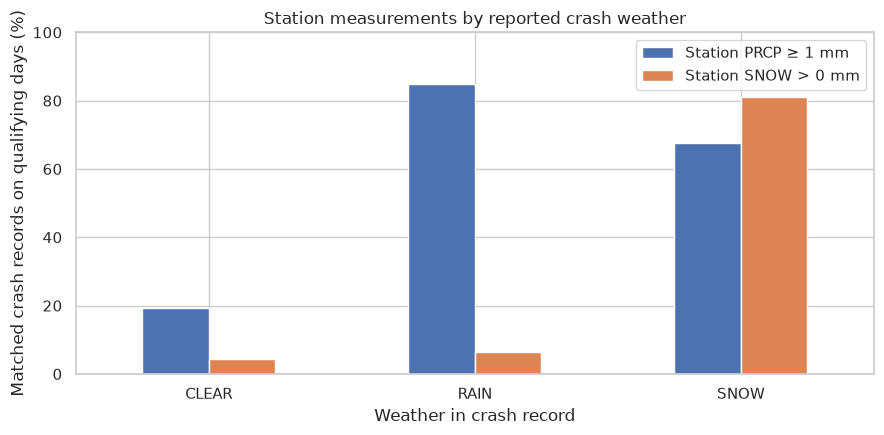

In [2]:
matched = period.merge(
    station[["date", "prcp_mm", "snow_valid_mm"]],
    left_on="crash_day", right_on="date", how="left", validate="many_to_one", indicator=True,
)
unmatched = matched["_merge"].eq("left_only")
print(f"Q3 date join: {len(period):,} -> {len(matched):,} crash rows")
print(f"Unmatched crash rows: {unmatched.sum():,}; unmatched distinct crash dates: {matched.loc[unmatched, 'crash_day'].nunique():,}")
assert len(matched) == len(period)

weather_order = ["CLEAR", "RAIN", "SNOW"]
agreement = restrict(matched, matched["weather_condition"].isin(weather_order), "Q3 exact clear, rain and snow labels")
agreement = restrict(
    agreement, agreement[["prcp_mm", "snow_valid_mm"]].notna().all(axis=1),
    "Q3 require valid PRCP and SNOW for weather comparison",
)
agreement["wet_at_station"] = agreement["prcp_mm"].ge(1.0)
agreement["any_prcp"] = agreement["prcp_mm"].gt(0)
agreement["snow_at_station"] = agreement["snow_valid_mm"].gt(0)

station_compare = agreement.groupby("weather_condition", observed=True).agg(
    crashes=("crash_day", "size"), unique_dates=("crash_day", "nunique"),
    wet_fraction=("wet_at_station", "mean"), any_prcp_fraction=("any_prcp", "mean"),
    snow_fraction=("snow_at_station", "mean"), median_prcp_mm=("prcp_mm", "median"),
).reindex(weather_order)
station_metrics = ["wet_fraction", "any_prcp_fraction", "snow_fraction"]
station_compare[station_metrics] *= 100
display(station_compare.rename(columns={col: col.replace("_fraction", "_pct") for col in station_metrics}).round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
station_compare[["wet_fraction", "snow_fraction"]].rename(
    columns={"wet_fraction": "Station PRCP ≥ 1 mm", "snow_fraction": "Station SNOW > 0 mm"}
).plot(kind="bar", ax=ax, rot=0)
ax.set(title="Station measurements by reported crash weather", xlabel="Weather in crash record", ylabel="Matched crash records on qualifying days (%)", ylim=(0, 100))
ax.legend()
fig.tight_layout()
plt.show()

## Compare injury outcomes at the same recorded surface and lighting

The injury comparison uses the crash report condition, independent of whether NOAA has a valid reading on that day. Restrict to known, interpretable surface labels and lighting. For each of the two comparisons, keep surface/lighting combinations with at least 50 records in **both** the hazardous-weather and clear groups. This common-support filter limits comparisons to combinations represented in the data. It yields different subsets for rain and snow.

Within each supported combination, calculate the outcome share. Then average the shares for both weather groups using the same stratum weights. The primary weights are proportional to the smaller of the two group counts in each stratum. This prioritizes combinations with substantial representation in both groups. As a sensitivity check, we instead use weights proportional to the total number of records from both groups, which gives more influence to imbalanced strata. Both standardized estimates are reported alongside the crude difference on the same supported records.

Resample whole Monday–Sunday weeks 1,000 times with replacement, recalculate weights and injury shares, and take the 2.5th and 97.5th percentiles of the adjusted difference. This preserves dependence among records in the same sampled week. The intervals remain conditional on the snapshot, the selected strata, and the assumption that weeks are comparable resampling units.

Surface conditions can be consequences of weather. The adjusted results describe weather associations conditional on surface and lighting and should not be interpreted as total causal effects.

In [3]:
paired_weather = restrict(period, period["weather_condition"].isin(weather_order), "Q3 compare clear, rain and snow")
valid_surface = ["DRY", "WET", "SNOW OR SLUSH", "ICE"]
valid_light = ["DAYLIGHT", "DARKNESS, LIGHTED ROAD", "DARKNESS", "DAWN", "DUSK"]
known_conditions = restrict(
    paired_weather, paired_weather["roadway_surface_cond"].isin(valid_surface),
    "Q3 retain the four prespecified surface categories",
)
known_conditions = restrict(
    known_conditions, known_conditions["lighting_condition"].isin(valid_light),
    "Q3 retain known lighting conditions",
)
known_conditions["stratum"] = known_conditions["roadway_surface_cond"] + " / " + known_conditions["lighting_condition"]
known_conditions["week"] = known_conditions["crash_day"].dt.to_period("W-SUN")
display(event_summary(paired_weather, ["weather_condition"], "has_injury").round(2))

Q3 compare clear, rain and snow: 181,051 -> 167,055 rows (13,996 excluded)
Q3 retain the four prespecified surface categories: 167,055 -> 161,623 rows (5,432 excluded)
Q3 retain known lighting conditions: 161,623 -> 161,199 rows (424 excluded)


,weather_condition,crashes,events,pct,low_pct,high_pct
0,CLEAR,142467,39095,27.44,27.21,27.67
1,RAIN,18646,5533,29.67,29.02,30.33
2,SNOW,5942,1346,22.65,21.61,23.73


In [4]:
outcomes = {"Any injury": "has_injury", "Severe injury": "has_severe_injury"}


def standardized_rates(counts, pooled=False):
    # Shape: surface/light stratum × weather group × (count, injuries, severe injuries)
    totals = counts[:, :, 0]
    weight_counts = totals.sum(axis=1) if pooled else totals.min(axis=1)
    weights = weight_counts / weight_counts.sum()
    rates = counts[:, :, 1:] / totals[:, :, None]
    return 100 * (rates * weights[:, None, None]).sum(axis=0)


def compare_weather(label, seed=42):
    groups = ["CLEAR", label]
    pair = restrict(
        known_conditions, known_conditions["weather_condition"].isin(groups),
        f"Q3 comparison: {label} versus clear",
    )
    overlap = pd.crosstab(pair["stratum"], pair["weather_condition"]).reindex(columns=groups, fill_value=0)
    supported = overlap.index[overlap.ge(50).all(axis=1)]
    print(f"Surface/light strata with support in both weather groups: {len(supported)} of {len(overlap)}")
    shared = restrict(pair, pair["stratum"].isin(supported), f"Q3 common support for {label} comparison")
    assert len(supported) > 0
    support_table = overlap.loc[supported].copy()
    overlap_counts = support_table.min(axis=1)
    pooled_counts = support_table.sum(axis=1)
    support_table["overlap_weight_pct"] = 100 * overlap_counts / overlap_counts.sum()
    support_table["pooled_weight_pct"] = 100 * pooled_counts / pooled_counts.sum()
    display(support_table.round(2))
    weeks = pd.period_range(period["week"].min(), period["week"].max(), freq="W-SUN")
    full_index = pd.MultiIndex.from_product(
        [weeks, supported, groups], names=["week", "stratum", "weather_condition"]
    )
    counts = (
        shared.groupby(["week", "stratum", "weather_condition"], observed=True)
        .agg(crashes=("has_injury", "size"), any_injury=("has_injury", "sum"), severe=("has_severe_injury", "sum"))
        .reindex(full_index, fill_value=0).to_numpy()
        .reshape(len(weeks), len(supported), len(groups), 3)
    )
    total = counts.sum(axis=0)
    by_group = total.sum(axis=0)
    crude = 100 * by_group[:, 1:] / by_group[:, [0]]
    adjusted = standardized_rates(total)
    pooled = standardized_rates(total, pooled=True)

    rng = np.random.default_rng(seed)
    replicates = []
    for _ in range(1000):
        sampled = counts[rng.integers(0, len(weeks), size=len(weeks))].sum(axis=0)
        if (sampled[:, :, 0] == 0).any():
            continue
        rates = standardized_rates(sampled)
        replicates.append(rates[1] - rates[0])
    print(f"Bootstrap replicates with cells present: {len(replicates):,}/1,000")
    assert len(replicates) >= 900
    low, high = np.percentile(replicates, [2.5, 97.5], axis=0)
    return pd.DataFrame({
        "weather": label, "outcome": list(outcomes),
        "clear_crashes": by_group[0, 0], "exposed_crashes": by_group[1, 0],
        "crude_clear_pct": crude[0], "crude_exposed_pct": crude[1],
        "crude_difference_pp": crude[1] - crude[0],
        "adjusted_clear_pct": adjusted[0], "adjusted_exposed_pct": adjusted[1],
        "adjusted_difference_pp": adjusted[1] - adjusted[0], "low_pp": low, "high_pp": high,
        "pooled_weight_difference_pp": pooled[1] - pooled[0],
    })


period["week"] = period["crash_day"].dt.to_period("W-SUN")
q3_effects = pd.concat([compare_weather("RAIN", seed=42), compare_weather("SNOW", seed=43)], ignore_index=True)
display(q3_effects.round(2))

Q3 comparison: RAIN versus clear: 161,199 -> 155,351 rows (5,848 excluded)
Surface/light strata with support in both weather groups: 7 of 20


Q3 common support for RAIN comparison: 155,351 -> 143,802 rows (11,549 excluded)


weather_condition,CLEAR,RAIN,overlap_weight_pct,pooled_weight_pct
stratum,,,,
"DRY / DARKNESS, LIGHTED ROAD",31552,87,1.41,22.00
DRY / DAYLIGHT,88208,257,4.17,61.52
WET / DARKNESS,259,1004,4.20,0.88
"WET / DARKNESS, LIGHTED ROAD",2001,6263,32.46,5.75
WET / DAWN,153,495,2.48,0.45
WET / DAYLIGHT,3237,9397,52.51,8.79
WET / DUSK,171,718,2.77,0.62


Bootstrap replicates with cells present: 1,000/1,000
Q3 comparison: SNOW versus clear: 161,199 -> 142,835 rows (18,364 excluded)
Surface/light strata with support in both weather groups: 10 of 20


Q3 common support for SNOW comparison: 142,835 -> 100,912 rows (41,923 excluded)


weather_condition,CLEAR,SNOW,overlap_weight_pct,pooled_weight_pct
stratum,,,,
DRY / DAYLIGHT,88208,71,2.29,87.48
"ICE / DARKNESS, LIGHTED ROAD",178,98,3.17,0.27
ICE / DAYLIGHT,346,124,4.01,0.47
"SNOW OR SLUSH / DARKNESS, LIGHTED ROAD",309,1337,9.99,1.63
SNOW OR SLUSH / DAYLIGHT,698,1928,22.56,2.60
WET / DARKNESS,259,86,2.78,0.34
"WET / DARKNESS, LIGHTED ROAD",2001,599,19.36,2.58
WET / DAWN,153,50,1.62,0.20
WET / DAYLIGHT,3237,997,32.22,4.20


Bootstrap replicates with cells present: 1,000/1,000


,weather,outcome,clear_crashes,exposed_crashes,crude_clear_pct,crude_exposed_pct,crude_difference_pp,adjusted_clear_pct,adjusted_exposed_pct,adjusted_difference_pp,low_pp,high_pp,pooled_weight_difference_pp
0,RAIN,Any injury,125581,18221,27.81,29.75,1.94,28.00,29.39,1.38,0.16,2.57,-3.94
1,RAIN,Severe injury,125581,18221,3.56,3.35,-0.21,3.41,3.29,-0.12,-0.66,0.38,-1.27
2,SNOW,Any injury,95560,5352,26.51,22.83,-3.68,24.38,25.27,0.89,-1.00,2.84,0.31
3,SNOW,Severe injury,95560,5352,3.20,2.11,-1.09,2.90,2.53,-0.37,-1.05,0.31,-1.61


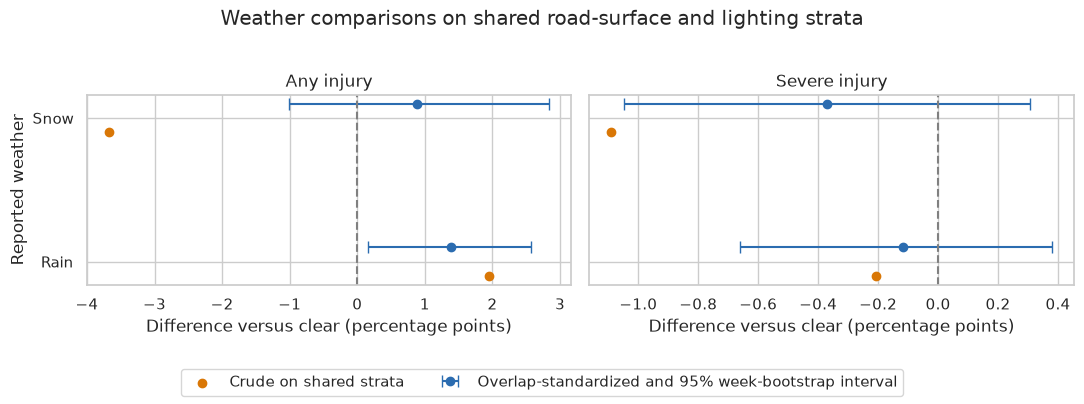

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (outcome, table) in zip(axes, q3_effects.groupby("outcome", sort=False)):
    y = np.arange(len(table))
    ax.scatter(table["crude_difference_pp"], y - .1, label="Crude on shared strata", color="#D97706")
    ax.errorbar(
        table["adjusted_difference_pp"], y + .1,
        xerr=np.vstack([table["adjusted_difference_pp"] - table["low_pp"], table["high_pp"] - table["adjusted_difference_pp"]]),
        fmt="o", capsize=4, color="#2B6CB0", label="Overlap-standardized and 95% week-bootstrap interval",
    )
    ax.axvline(0, linestyle="--", color="gray")
    ax.set_yticks(y, table["weather"].str.title())
    ax.set(title=outcome, xlabel="Difference versus clear (percentage points)")
axes[0].set_ylabel("Reported weather")
handles, figure_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, figure_labels, loc="lower center", ncol=2)
fig.suptitle("Weather comparisons on shared road-surface and lighting strata")
fig.tight_layout(rect=(0, .12, 1, .96))
plt.show()

## Results and interpretation

The date join kept **181,051** crash records and left **0 unmatched crash dates**. Among the exact report categories, **84.80%** of rain records fell on an O’Hare day with at least 1 mm of precipitation, versus **19.21%** for clear records. For any positive PRCP the shares were **92.55%** and **26.60%**, respectively. For snow records, **81.05%** occurred on a station day with measurable snowfall, compared with **4.25%** of clear records. The station observations distinguish the report groups, with expected disagreement between a daily airport measurement and the conditions at an individual crash.

Using the primary overlap weights, the any-injury share for rain was **29.39%**, versus **28.00%** for its comparable clear group. The difference was **+1.38 percentage points** (95% week-bootstrap interval **+0.16 to +2.57**). The snow difference was **+0.89 points** (**−1.00 to +2.84**), with substantial uncertainty. Severe-injury differences were **−0.12 points** for rain (**−0.66 to +0.38**) and **−0.37 points** for snow (**−1.05 to +0.31**).

The rain estimate changed sign under pooled weights (**−3.94 points** for any injury). For example, dry daylight received **61.52%** of the pooled weight but had only **257** rain records alongside **88,208** clear records. In the primary analysis it received **4.17%** of weight. The results support a small positive rain association in comparable conditions represented by the primary weights. They do not support a broadly stable increase across weighting choices, a clear increase for snow, or an increase in severe injury. The data lack traffic exposure and can neither isolate the effect of weather nor capture its full effect when road surface is held fixed.

AI contributions to code and draft interpretation are recorded in `LLM_USAGE.md`.